# SANOS-EKF observation sweep — effect of smoothing on held-out out-of-spread %

Compares the SANOS-EKF across the **9 complete trade dates** in `sweep_SPY_2024-01-03_to_2024-01-17.csv`, **calls and puts kept separate throughout**. (2024-01-17 is dropped — the sweep produced no `smoothed` runs for it.)

The observation axis (`obs_mode`) is the smoothing switch:
* **`intrinsic`** — η = 0, the exact tridiagonal SANOS density priced against discrete (intrinsic) calls.
* **`smoothed`** — η > 0, each node priced as a lognormal of variance η·V_ATM (paper §3.1). Swept at η ∈ {0.06, 0.5}.

`ho_out_pct` = **% of held-out quotes the model prices outside the bid–ask spread** — lower is better.

The clean way to isolate smoothing: every shared-parameter set in the grid has an `intrinsic` row **plus** `smoothed@0.06` and `smoothed@0.5` rows. Holding all other EKF params fixed and toggling only smoothing is a matched A/B — that is what §A below does.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CSV = "/Users/elie/Documents/GitHub/quant_data/personal/SANOS_KF/sweep_SPY_2024-01-03_to_2024-01-17.csv"
df = pd.read_csv(CSV)
df = df[df["ok"]].copy()
# 2024-01-17 has only intrinsic runs (no smoothed) — drop it so every day is complete.
df = df[df["date"] != "2024-01-17"].copy()

# Smoothing variant label: the single axis we are studying.
df["variant"] = np.where(
    df["obs_mode"] == "intrinsic", "intrinsic", "smoothed@" + df["eta"].astype("string")
)
# Everything EXCEPT the smoothing axis identifies a matched grid point.
SHARED = [
    "sigmoid_mode",
    "Sigma_init",
    "Q_scale_dlv",
    "P0_scale",
    "ell",
    "max_dlvsq",
    "use_sigmoid",
]
DATES = sorted(df["date"].unique())
VARIANTS = ["intrinsic", "smoothed@0.06", "smoothed@0.5"]

print(f"{len(df):,} rows | {len(DATES)} dates: {DATES[0]} .. {DATES[-1]}")
print("variants:", df["variant"].value_counts().to_dict())
print("rows per side:", df["side"].value_counts().to_dict())

1,008 rows | 9 dates: 2024-01-03 .. 2024-01-16
variants: {'intrinsic': 336, 'smoothed@0.06': 336, 'smoothed@0.5': 336}
rows per side: {'calls': 504, 'puts': 504}


## A. Precise smoothing effect — matched A/B (all other params held fixed)

Pivot each `(date, side, shared-params)` group so the three smoothing variants sit side by side, then take the **Δ in `ho_out_pct` vs the intrinsic (η=0) baseline**. Δ < 0 means smoothing pushes fewer held-out quotes outside the spread (an improvement).

In [2]:
piv = df.pivot_table(
    index=["date", "side"] + SHARED,
    columns="variant",
    values="ho_out_pct_mean",
    dropna=False,
)
# keep only matched groups that actually have the intrinsic baseline + both smoothings
matched = piv.dropna(subset=VARIANTS).copy()
matched["d_0.06"] = matched["smoothed@0.06"] - matched["intrinsic"]
matched["d_0.5"] = matched["smoothed@0.5"] - matched["intrinsic"]
matched = matched.reset_index()

print(f"{len(matched)} matched grid points (per date×side×shared-params)\n")

summary = (
    matched.groupby("side")
    .agg(
        intrinsic_mean=("intrinsic", "mean"),
        sm006_mean=("smoothed@0.06", "mean"),
        sm05_mean=("smoothed@0.5", "mean"),
        d006_mean=("d_0.06", "mean"),
        d006_med=("d_0.06", "median"),
        d006_winfrac=("d_0.06", lambda s: (s < 0).mean()),
        d05_mean=("d_0.5", "mean"),
        d05_med=("d_0.5", "median"),
        d05_winfrac=("d_0.5", lambda s: (s < 0).mean()),
    )
    .round(3)
)
print(
    "Mean ho_out_pct by smoothing variant, and Δ vs intrinsic (winfrac = share of configs where smoothing helps):"
)
summary

336 matched grid points (per date×side×shared-params)

Mean ho_out_pct by smoothing variant, and Δ vs intrinsic (winfrac = share of configs where smoothing helps):


,intrinsic_mean,sm006_mean,sm05_mean,d006_mean,d006_med,d006_winfrac,d05_mean,d05_med,d05_winfrac
side,,,,,,,,,
calls,6.993,6.634,7.777,-0.360,-0.301,0.869,0.784,0.598,0.286
puts,15.125,14.484,19.194,-0.641,-0.207,0.875,4.068,2.934,0.149


In [3]:
# Same matched Δ, broken out per day so day-to-day stability is visible (calls vs puts).
for side in ["calls", "puts"]:
    sub = matched[matched["side"] == side]
    tbl = (
        sub.groupby("date")[["intrinsic", "smoothed@0.06", "smoothed@0.5", "d_0.06", "d_0.5"]]
        .mean()
        .round(3)
    )
    print(f"\n[{side}] mean ho_out_pct per day, averaged over matched grid points:")
    print(tbl.to_string())


[calls] mean ho_out_pct per day, averaged over matched grid points:
variant     intrinsic  smoothed@0.06  smoothed@0.5  d_0.06  d_0.5
date                                                             
2024-01-03      9.602          9.941        10.343   0.340  0.741
2024-01-04      7.503          7.020         8.508  -0.483  1.005
2024-01-05      7.463          6.789         6.962  -0.674 -0.502
2024-01-08      5.583          5.060         7.405  -0.523  1.822
2024-01-09      6.383          5.463         6.434  -0.920  0.051
2024-01-10      4.424          3.896         4.447  -0.528  0.023
2024-01-11      6.288          5.780         6.284  -0.508 -0.004
2024-01-12      5.713          5.224         7.907  -0.489  2.194
2024-01-16      6.068          5.569         7.858  -0.499  1.790

[puts] mean ho_out_pct per day, averaged over matched grid points:
variant     intrinsic  smoothed@0.06  smoothed@0.5  d_0.06  d_0.5
date                                                             
2024-

## B. Day-by-day winners — best EKF parameters per side

For each `(date, side)` pick the single best grid point by `ho_nse_mean` and report its parameters and `ho_out_pct`. Shows how the optimal EKF config drifts across the 9 days, and which smoothing variant wins each day.

In [4]:
PARAM_COLS = [
    "variant",
    "sigmoid_mode",
    "Sigma_init",
    "Q_scale_dlv",
    "P0_scale",
    "ell",
    "max_dlvsq",
]
best = df.loc[df.groupby(["date", "side"])["ho_nse_mean"].idxmin()]
for side in ["calls", "puts"]:
    cols = ["date"] + PARAM_COLS + ["ho_nse_mean", "ho_out_pct_mean", "is_out_pct_mean"]
    tbl = best[best["side"] == side][cols].sort_values("date").round(4)
    print(f"\n[{side}] best config per day (by ho_nse_mean):")
    with pd.option_context("display.max_columns", None, "display.width", 220):
        print(tbl.to_string(index=False))


[calls] best config per day (by ho_nse_mean):
      date   variant sigmoid_mode  Sigma_init  Q_scale_dlv  P0_scale  ell  max_dlvsq  ho_nse_mean  ho_out_pct_mean  is_out_pct_mean
2024-01-03 intrinsic      sigmoid        0.01          1.0      0.01  1.0       10.0       0.2696           4.5445           1.9963
2024-01-04 intrinsic      sigmoid        0.01          1.0      0.01  1.0       10.0       0.3348           6.7237           2.8397
2024-01-05 intrinsic      sigmoid        0.01          1.0      0.01  1.0       10.0       0.3246           6.6657           3.0592
2024-01-08 intrinsic      sigmoid        0.01          1.0      0.01  1.0       10.0       0.2756           4.5782           1.7287
2024-01-09 intrinsic      sigmoid        0.01          1.0      0.01  1.0       10.0       0.3017           5.1200           1.9203
2024-01-10 intrinsic      sigmoid        0.01          1.0      0.01  1.0       10.0       0.2504           3.5881           1.2625
2024-01-11 intrinsic      sig

In [5]:
# Best-achievable ho_out_pct per smoothing variant per day: for each (date, side, variant)
# take the grid point with the lowest ho_out_pct_mean. Isolates the smoothing ceiling.
best_var = df.groupby(["date", "side", "variant"])["ho_out_pct_mean"].min().reset_index()
for side in ["calls", "puts"]:
    tbl = (
        best_var[best_var["side"] == side]
        .pivot(index="date", columns="variant", values="ho_out_pct_mean")[VARIANTS]
        .round(3)
    )
    tbl.loc["MEAN"] = tbl.mean().round(3)
    print(f"\n[{side}] best ho_out_pct_mean achievable per variant, per day:")
    print(tbl.to_string())


[calls] best ho_out_pct_mean achievable per variant, per day:
variant     intrinsic  smoothed@0.06  smoothed@0.5
date                                              
2024-01-03      4.486          4.460         4.698
2024-01-04      6.719          6.605         7.440
2024-01-05      6.666          6.550         6.461
2024-01-08      4.569          4.472         5.658
2024-01-09      5.116          5.000         5.402
2024-01-10      3.584          3.490         3.825
2024-01-11      5.568          5.477         5.859
2024-01-12      4.897          4.805         6.879
2024-01-16      5.380          5.287         6.701
MEAN            5.221          5.127         5.880

[puts] best ho_out_pct_mean achievable per variant, per day:
variant     intrinsic  smoothed@0.06  smoothed@0.5
date                                              
2024-01-03     11.741         11.710        18.274
2024-01-04     11.684         11.624        12.468
2024-01-05     11.595         11.522        12.446
2024-01-

## C. Plots

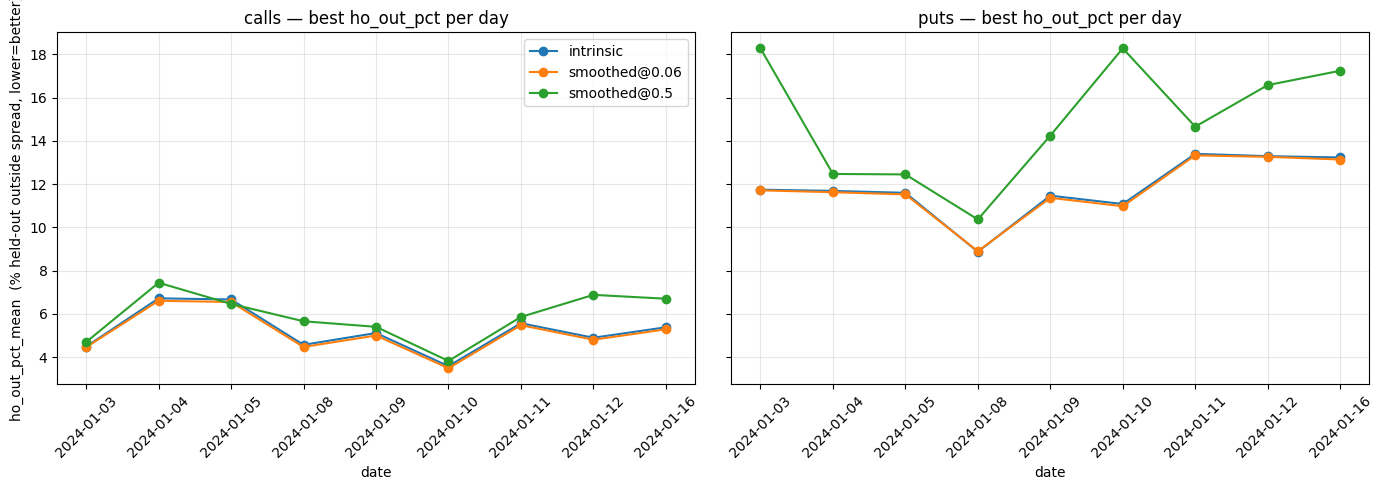

In [6]:
# ho_out_pct over the 10 days, one line per smoothing variant, calls vs puts side by side.
# Uses the best-achievable ho_out_pct per (date, side, variant) from §B.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
colors = {"intrinsic": "C0", "smoothed@0.06": "C1", "smoothed@0.5": "C2"}
for ax, side in zip(axes, ["calls", "puts"]):
    sub = best_var[best_var["side"] == side]
    for v in VARIANTS:
        s = sub[sub["variant"] == v].set_index("date")["ho_out_pct_mean"].reindex(DATES)
        ax.plot(DATES, s.values, marker="o", label=v, color=colors[v])
    ax.set_title(f"{side} — best ho_out_pct per day")
    ax.set_xlabel("date")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("ho_out_pct_mean  (% held-out outside spread, lower=better)")
axes[0].legend()
fig.tight_layout()
plt.show()

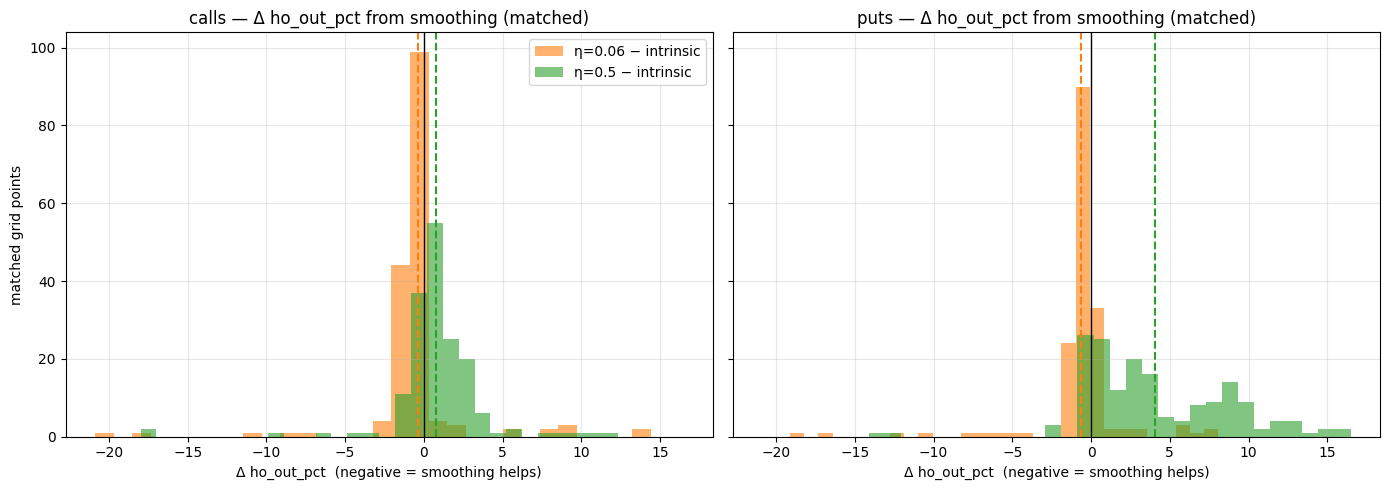

In [7]:
# Matched Δ distribution: how smoothing shifts ho_out_pct vs the intrinsic baseline,
# across all matched grid points. Vertical line at 0 = no effect; mass left of it = improvement.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, side in zip(axes, ["calls", "puts"]):
    sub = matched[matched["side"] == side]
    ax.hist(sub["d_0.06"], bins=30, alpha=0.6, label="η=0.06 − intrinsic", color="C1")
    ax.hist(sub["d_0.5"], bins=30, alpha=0.6, label="η=0.5 − intrinsic", color="C2")
    ax.axvline(0, color="k", lw=1)
    ax.axvline(sub["d_0.06"].mean(), color="C1", ls="--", lw=1.5)
    ax.axvline(sub["d_0.5"].mean(), color="C2", ls="--", lw=1.5)
    ax.set_title(f"{side} — Δ ho_out_pct from smoothing (matched)")
    ax.set_xlabel("Δ ho_out_pct  (negative = smoothing helps)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("matched grid points")
axes[0].legend()
fig.tight_layout()
plt.show()